# ✈️ Airport Flight Delay Analytics (India)
**Capstone Project – Data Science and Application**

**How to run in Google Colab:** `Runtime → Run all`. When the *Load data* cell runs, click **Choose files** and upload `india_flight_delay_model_input.csv`.

**Pipeline:** Load → Explore (EDA) → Feature engineering → Time-based split → Classification models → Evaluation → Feature importance → Delay-minutes regression → Predict a new flight → Save model

## 1. Setup

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve, mean_absolute_error,
                             mean_squared_error, r2_score, classification_report)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
RANDOM_STATE = 42

## 2. Load data

In [ ]:
CSV = "india_flight_delay_model_input.csv"

if not os.path.exists(CSV):
    from google.colab import files   # only works inside Colab
    uploaded = files.upload()        # choose india_flight_delay_model_input.csv
    CSV = list(uploaded.keys())[0]

df = pd.read_csv(CSV, parse_dates=["Flight_Date"])
print("Shape:", df.shape)
df.head()

Saving india_flight_delay_model_input.csv to india_flight_delay_model_input.csv
Shape: (150000, 23)


,Flight_Date,Airline,Flight_Number,Origin_Airport,Destination_Airport,Scheduled_Departure_Hour,Scheduled_Departure_Minute,Day_of_Week,Month,Is_Weekend,...,Humidity_pct,Wind_Speed_kmh,Visibility_km,Rainfall_mm,Cloud_Cover_pct,Origin_Congestion_Index,Previous_Flight_Delay_Minutes,Turnaround_Risk_Index,Departure_Delay,Delay_Target
0,2025-12-04,IndiGo,IN8723,BOM,DEL,13,57,3,12,0,...,46.1,4.3,9.8,5.2,0.0,63.5,0,23.9,43,1
1,2024-01-15,IndiGo,IN558,CCU,HYD,19,14,0,1,0,...,70.5,8.9,11.7,0.4,39.8,95.3,1,31.5,49,1
2,2023-11-06,Vistara,VI4949,HYD,DEL,8,50,0,11,0,...,53.7,7.8,9.6,4.3,16.6,100.0,1,41.5,73,1
3,2025-08-08,SpiceJet,SP3196,BLR,DIB,11,56,4,8,0,...,42.0,1.5,12.6,4.6,23.6,51.1,1,28.2,40,1
4,2023-09-09,IndiGo,IN8458,BLR,JGA,22,59,5,9,1,...,58.5,1.3,11.3,3.5,36.2,67.0,0,27.9,0,0


In [ ]:
df.info()
print("\nMissing values:", df.isna().sum().sum(), "| Duplicate rows:", df.duplicated().sum())
print("Date range:", df.Flight_Date.min().date(), "→", df.Flight_Date.max().date())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 23 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   Flight_Date                    150000 non-null  datetime64[ns]
 1   Airline                        150000 non-null  object        
 2   Flight_Number                  150000 non-null  object        
 3   Origin_Airport                 150000 non-null  object        
 4   Destination_Airport            150000 non-null  object        
 5   Scheduled_Departure_Hour       150000 non-null  int64         
 6   Scheduled_Departure_Minute     150000 non-null  int64         
 7   Day_of_Week                    150000 non-null  int64         
 8   Month                          150000 non-null  int64         
 9   Is_Weekend                     150000 non-null  int64         
 10  Peak_Hour                      150000 non-null  int64         
 11  

,count,mean,min,25%,50%,75%,max,std
Flight_Date,150000,2024-06-30 02:34:46.848000256,2023-01-01 00:00:00,2023-10-01 00:00:00,2024-06-29 00:00:00,2025-03-31 00:00:00,2025-12-30 00:00:00,NaN
Scheduled_Departure_Hour,150000.0,14.00126,5.0,9.0,14.0,19.0,23.0,5.480291
Scheduled_Departure_Minute,150000.0,29.533773,0.0,15.0,30.0,45.0,59.0,17.322034
Day_of_Week,150000.0,2.997107,0.0,1.0,3.0,5.0,6.0,2.003977
Month,150000.0,6.512973,1.0,4.0,7.0,10.0,12.0,3.445167
Is_Weekend,150000.0,0.28682,0.0,0.0,0.0,1.0,1.0,0.452278
Peak_Hour,150000.0,0.47528,0.0,0.0,0.0,1.0,1.0,0.49939
Temperature_C,150000.0,27.028051,10.0,22.9,27.0,31.1,45.0,5.489234
Humidity_pct,150000.0,56.332991,20.0,49.5,56.3,63.2,100.0,10.161597
Wind_Speed_kmh,150000.0,5.993765,0.0,2.9,5.0,8.1,35.0,4.223185


## 3. Understanding the target & data-leakage check
`Delay_Target` is derived from `Departure_Delay` (0 = on time, 1 = delayed). Let's confirm.

In [ ]:
print(df.groupby("Delay_Target")["Departure_Delay"].agg(["min", "max", "mean", "count"]))
print("\nClass balance:\n", df.Delay_Target.value_counts(normalize=True).round(3))

              min  max       mean   count
Delay_Target                             
0               0    0   0.000000   20075
1              19  119  49.256502  129925

Class balance:
 Delay_Target
1    0.866
0    0.134
Name: proportion, dtype: float64


**Findings**
- Every `Delay_Target = 0` flight has 0 minutes delay, every `Delay_Target = 1` flight has ≥ 19 minutes. So **`Departure_Delay` must NOT be used as a feature** for classification (it would leak the answer).
- The classes are imbalanced (~87 % delayed), so **accuracy alone is misleading** – we use Precision, Recall, F1, ROC-AUC and PR-AUC.
- The distribution looks simulated (real Indian delay rates are far lower). State this in your report; results describe *this dataset*.

## 4. Exploratory Data Analysis

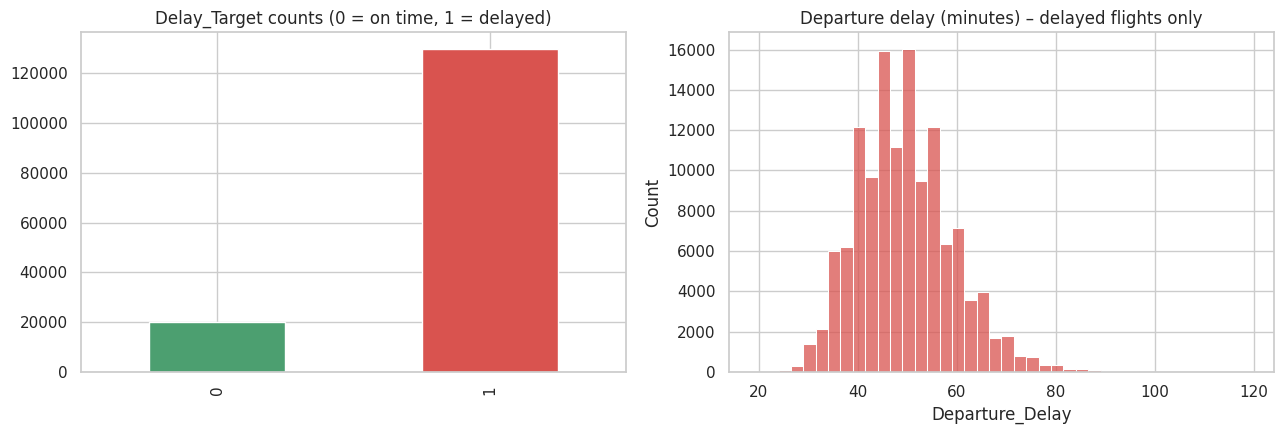

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
df.Delay_Target.value_counts().sort_index().plot(kind="bar", ax=ax[0], color=["#4C9F70", "#D9534F"])
ax[0].set_title("Delay_Target counts (0 = on time, 1 = delayed)"); ax[0].set_xlabel("")
sns.histplot(df[df.Departure_Delay > 0].Departure_Delay, bins=40, ax=ax[1], color="#D9534F")
ax[1].set_title("Departure delay (minutes) – delayed flights only")
plt.tight_layout(); plt.show()

,flights,delay_rate,avg_delay_min
Airline,,,
Alliance Air,5915,0.878,43.236
SpiceJet,11739,0.876,43.045
Air India Express,15212,0.875,43.024
Star Air,6072,0.874,42.967
Fly91,3014,0.870,42.983
Air India,26875,0.869,42.712
IndiGo,60242,0.862,42.524
Vistara,8994,0.858,42.401
Akasa Air,11937,0.854,42.114


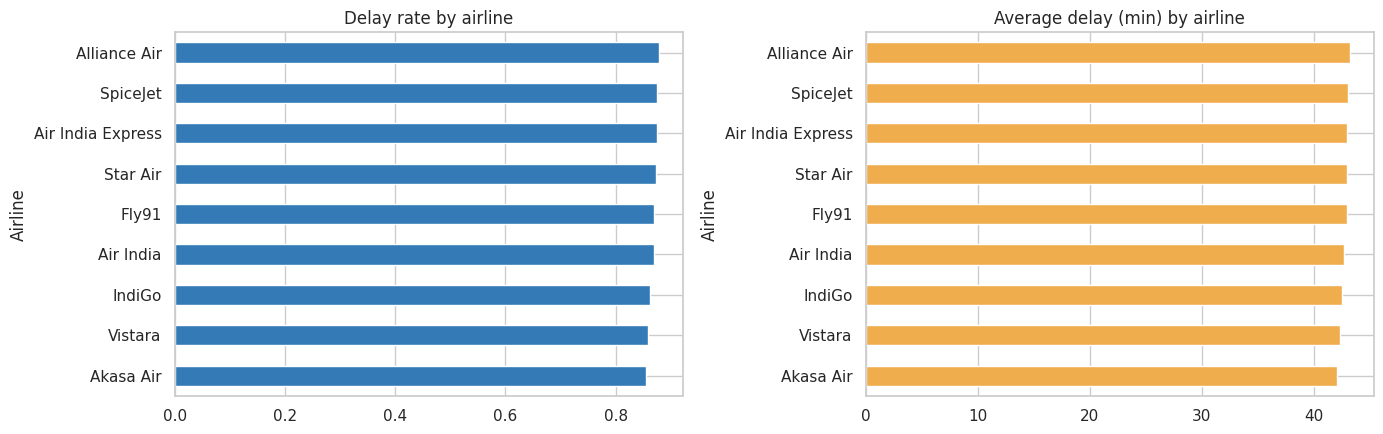

In [ ]:
airline = df.groupby("Airline").agg(flights=("Delay_Target", "size"),
                                    delay_rate=("Delay_Target", "mean"),
                                    avg_delay_min=("Departure_Delay", "mean")).sort_values("delay_rate", ascending=False)
display(airline.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
airline.delay_rate.plot(kind="barh", ax=ax[0], color="#337AB7"); ax[0].set_title("Delay rate by airline"); ax[0].invert_yaxis()
airline.avg_delay_min.plot(kind="barh", ax=ax[1], color="#F0AD4E"); ax[1].set_title("Average delay (min) by airline"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

Airports with ≥500 departures – highest average delay:


,flights,delay_rate,avg_delay_min,avg_congestion
Origin_Airport,,,,
COK,10184,0.93,46.29,77.75
MAA,13019,0.93,46.21,77.78
AMD,8579,0.93,46.14,77.68
CCU,11697,0.93,46.08,77.48
BOM,20363,0.92,45.96,77.43
DEL,26337,0.93,45.95,77.08
BLR,17398,0.92,45.92,77.42
HYD,14461,0.92,45.91,77.40


Lowest:


,flights,delay_rate,avg_delay_min,avg_congestion
Origin_Airport,,,,
CCU,11697,0.93,46.08,77.48
BOM,20363,0.92,45.96,77.43
DEL,26337,0.93,45.95,77.08
BLR,17398,0.92,45.92,77.42
HYD,14461,0.92,45.91,77.40


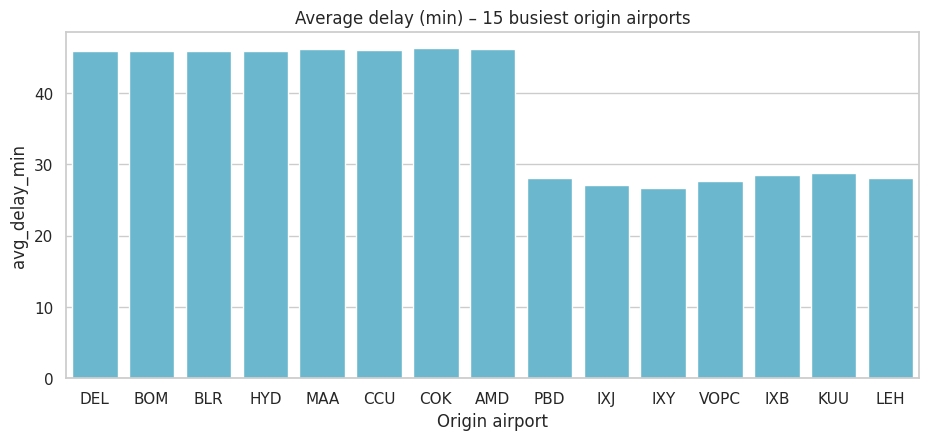

In [ ]:
airports = df.groupby("Origin_Airport").agg(flights=("Delay_Target", "size"),
                                            delay_rate=("Delay_Target", "mean"),
                                            avg_delay_min=("Departure_Delay", "mean"),
                                            avg_congestion=("Origin_Congestion_Index", "mean"))
top = airports[airports.flights >= 500].sort_values("avg_delay_min", ascending=False)
print("Airports with ≥500 departures – highest average delay:")
display(top.head(10).round(2))
print("Lowest:")
display(top.tail(5).round(2))

busiest = airports.sort_values("flights", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(x=busiest.index, y=busiest.avg_delay_min, ax=ax, color="#5BC0DE")
ax.set_title("Average delay (min) – 15 busiest origin airports"); ax.set_xlabel("Origin airport")
plt.show()

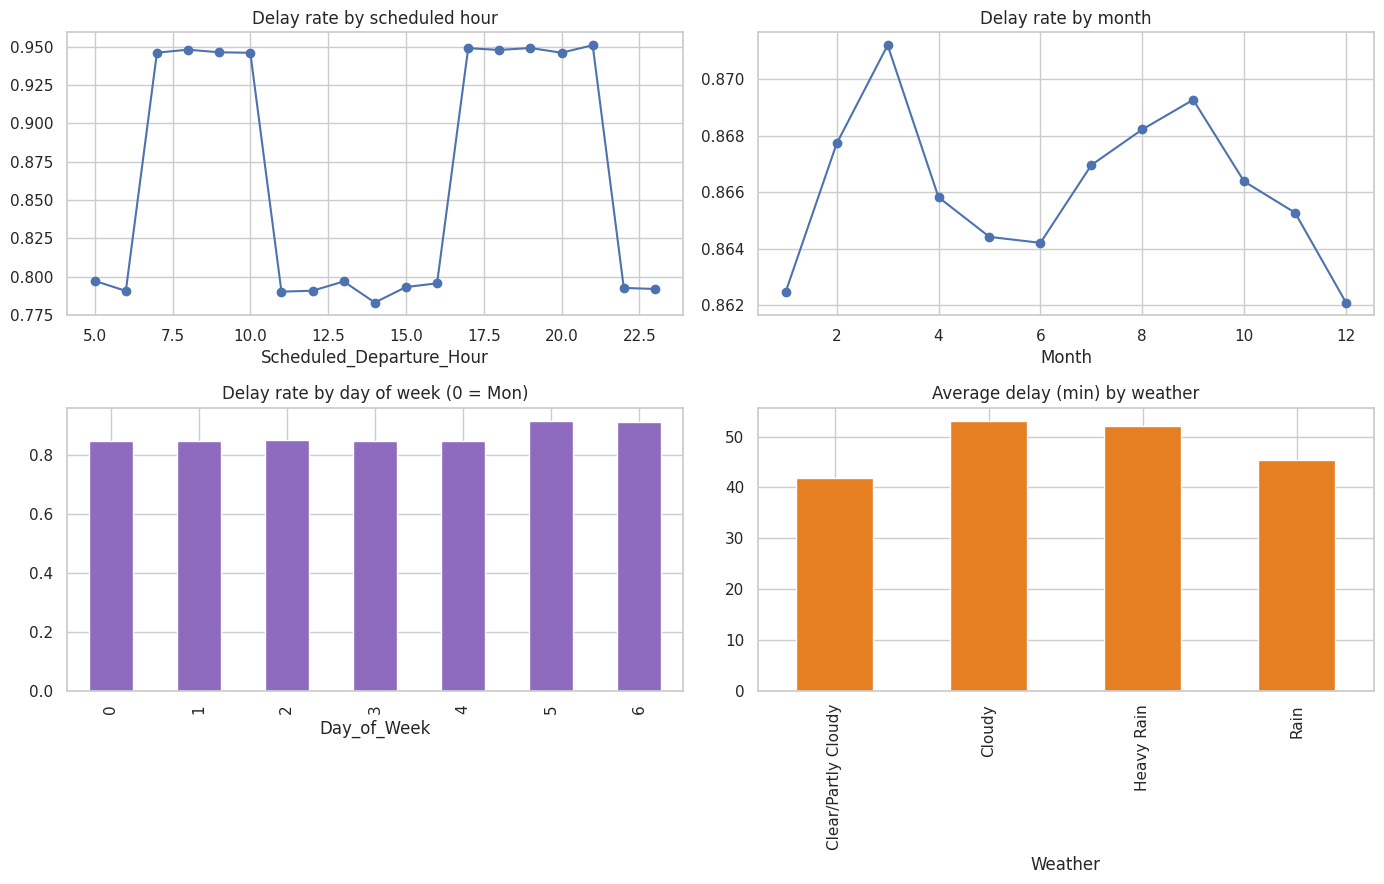

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
df.groupby("Scheduled_Departure_Hour").Delay_Target.mean().plot(marker="o", ax=ax[0,0]); ax[0,0].set_title("Delay rate by scheduled hour")
df.groupby("Month").Delay_Target.mean().plot(marker="o", ax=ax[0,1]); ax[0,1].set_title("Delay rate by month")
df.groupby("Day_of_Week").Delay_Target.mean().plot(kind="bar", ax=ax[1,0], color="#8E6BBF"); ax[1,0].set_title("Delay rate by day of week (0 = Mon)")
df.groupby("Weather").Departure_Delay.mean().plot(kind="bar", ax=ax[1,1], color="#E67E22"); ax[1,1].set_title("Average delay (min) by weather")
plt.tight_layout(); plt.show()

                 flights  delay_rate  avg_delay
Congestion_Band                                
Low                 9173       0.149      6.154
Medium             26666       0.713     30.341
High               59969       0.960     44.911
Very high          54192       0.959     52.422


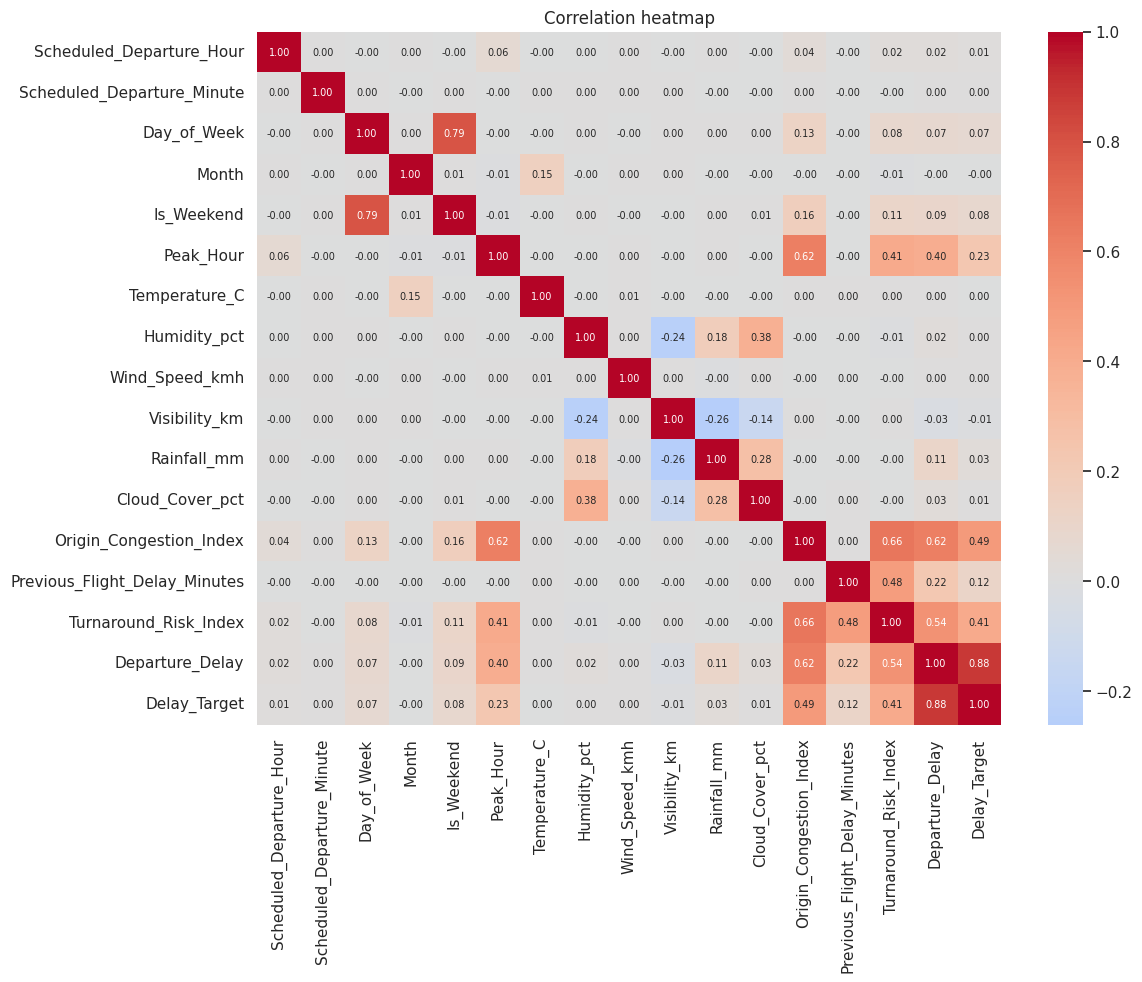

In [ ]:
df["Congestion_Band"] = pd.cut(df.Origin_Congestion_Index, [-1, 40, 60, 80, 100], labels=["Low", "Medium", "High", "Very high"])
print(df.groupby("Congestion_Band").agg(flights=("Delay_Target","size"), delay_rate=("Delay_Target","mean"), avg_delay=("Departure_Delay","mean")).round(3))
df.drop(columns="Congestion_Band", inplace=True)

num_cols = df.select_dtypes("number").columns
plt.figure(figsize=(12, 9))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation heatmap"); plt.show()

## 5. Feature engineering
- Extract `Year`, `DayOfYear` from the date (year is used only for the split, not as a feature).
- Merge the 4 rare `Cloudy` rows into `Clear/Partly Cloudy`.
- Drop `Flight_Number` (≈50 k unique values, no signal), `Flight_Date`, and the leaky `Departure_Delay`.
- Airline & Weather → one-hot. Origin/Destination airports (86 values) → **target encoding** (fit only on training data inside the pipeline, so there's no leakage).

In [ ]:
data = df.copy()
data["Year"] = data.Flight_Date.dt.year
data["Weather"] = data.Weather.replace({"Cloudy": "Clear/Partly Cloudy"})

TARGET_CLF = "Delay_Target"
TARGET_REG = "Departure_Delay"

cat_onehot = ["Airline", "Weather"]
cat_target = ["Origin_Airport", "Destination_Airport"]
numeric = ["Scheduled_Departure_Hour", "Scheduled_Departure_Minute", "Day_of_Week", "Month", "Is_Weekend", "Peak_Hour",
           "Temperature_C", "Humidity_pct", "Wind_Speed_kmh", "Visibility_km", "Rainfall_mm", "Cloud_Cover_pct",
           "Origin_Congestion_Index", "Previous_Flight_Delay_Minutes", "Turnaround_Risk_Index"]
FEATURES = numeric + cat_onehot + cat_target

# Time-based split: train on 2023-2024, test on 2025 (mimics real forecasting)
train = data[data.Year < 2025]
test = data[data.Year == 2025]
X_train, X_test = train[FEATURES], test[FEATURES]
y_train, y_test = train[TARGET_CLF], test[TARGET_CLF]
print(f"Train: {len(train):,} rows (2023–2024)  |  Test: {len(test):,} rows (2025)")
print("Delay rate  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

Train: 100,431 rows (2023–2024)  |  Test: 49,569 rows (2025)
Delay rate  train: 0.866  test: 0.866


In [ ]:
def make_preprocessor(scale=False):
    num_step = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("num", num_step, numeric),
        ("oh", OneHotEncoder(handle_unknown="ignore"), cat_onehot),
        ("te", TargetEncoder(random_state=RANDOM_STATE), cat_target),
    ])

## 6. Classification models: will the flight be delayed?

In [ ]:
models = {
    "Logistic Regression": Pipeline([("prep", make_preprocessor(scale=True)),
                                     ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Random Forest": Pipeline([("prep", make_preprocessor()),
                               ("clf", RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=5,
                                                              class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))]),
    "Gradient Boosting (HistGB)": Pipeline([("prep", make_preprocessor()),
                                            ("clf", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08,
                                                                                   class_weight="balanced", random_state=RANDOM_STATE))]),
}

rows, probas = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probas[name] = p
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, p),
                 "PR-AUC": average_precision_score(y_test, p)})
    print("done:", name)

results = pd.DataFrame(rows).set_index("Model").round(4)
results.sort_values("ROC-AUC", ascending=False)

done: Logistic Regression
done: Random Forest
done: Gradient Boosting (HistGB)


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Random Forest,0.9431,0.9591,0.9758,0.9674,0.8675,0.9614
Gradient Boosting (HistGB),0.9423,0.9601,0.9737,0.9669,0.8650,0.9597
Logistic Regression,0.8117,0.9598,0.8167,0.8825,0.8587,0.9581


Baseline to beat: always predicting *delayed* gives accuracy ≈ the delay rate (~87 %), which is why F1 / ROC-AUC / PR-AUC matter more.

Baseline accuracy (always 'delayed'): 0.8655


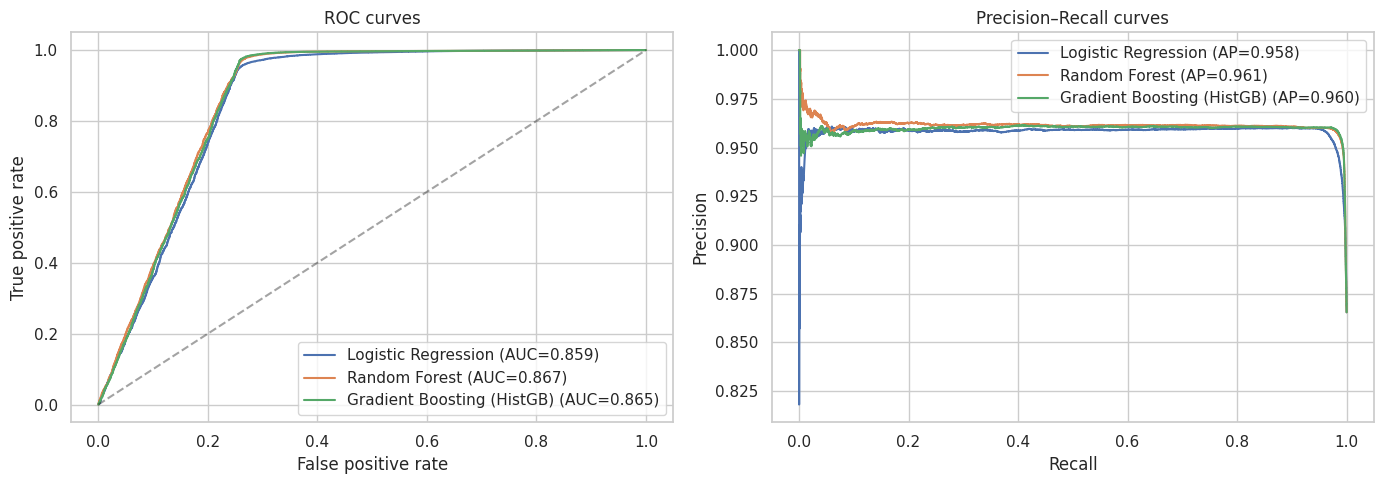

In [ ]:
print("Baseline accuracy (always 'delayed'): %.4f" % y_test.mean())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); ax[1].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", alpha=.4); ax[0].set_title("ROC curves"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend()
ax[1].set_title("Precision–Recall curves"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
plt.tight_layout(); plt.show()

Best model by ROC-AUC: Random Forest
              precision    recall  f1-score   support

     On time       0.82      0.73      0.78      6666
     Delayed       0.96      0.98      0.97     42903

    accuracy                           0.94     49569
   macro avg       0.89      0.85      0.87     49569
weighted avg       0.94      0.94      0.94     49569



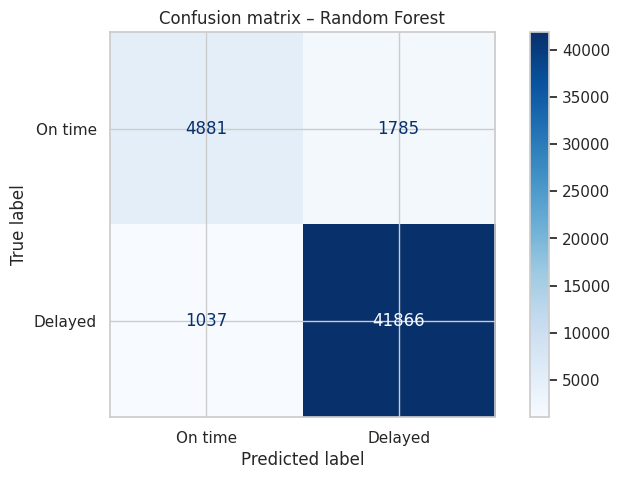

In [ ]:
best_name = results["ROC-AUC"].idxmax()
best_model = models[best_name]
print("Best model by ROC-AUC:", best_name)

pred = (probas[best_name] >= 0.5).astype(int)
print(classification_report(y_test, pred, target_names=["On time", "Delayed"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["On time", "Delayed"]).plot(cmap="Blues")
plt.title(f"Confusion matrix – {best_name}"); plt.show()

### Choosing a decision threshold
0.5 is not always best. Airlines/airports may prefer to catch more delays (higher recall) or avoid false alarms (higher precision).

,threshold,precision,recall,f1
0,0.10,0.933,0.997,0.964
1,0.15,0.942,0.996,0.968
2,0.20,0.947,0.994,0.970
3,0.25,0.951,0.992,0.971
4,0.30,0.954,0.990,0.971
5,0.35,0.956,0.987,0.971
6,0.40,0.957,0.984,0.970
7,0.45,0.958,0.980,0.969
8,0.50,0.959,0.976,0.967
9,0.55,0.960,0.972,0.966


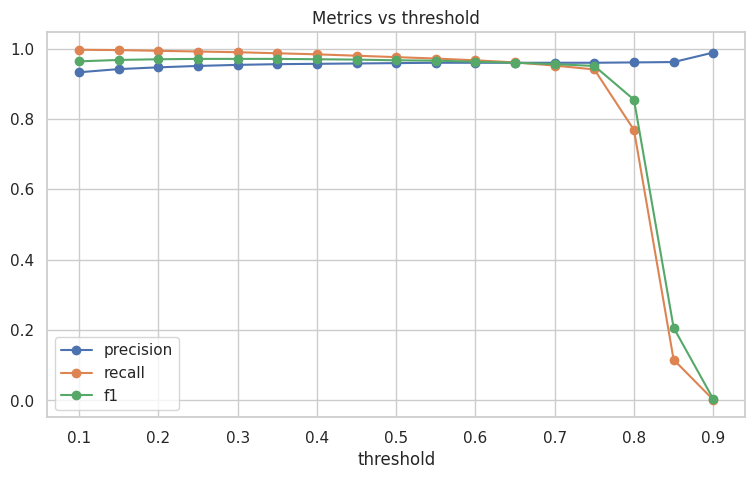

In [ ]:
p = probas[best_name]
ths = np.arange(0.1, 0.95, 0.05)
tab = pd.DataFrame({"threshold": ths,
                    "precision": [precision_score(y_test, p >= t) for t in ths],
                    "recall": [recall_score(y_test, p >= t) for t in ths],
                    "f1": [f1_score(y_test, p >= t) for t in ths]}).round(3)
display(tab)
tab.set_index("threshold")[["precision", "recall", "f1"]].plot(marker="o"); plt.title("Metrics vs threshold"); plt.show()

## 7. Which factors drive delays? (permutation importance)

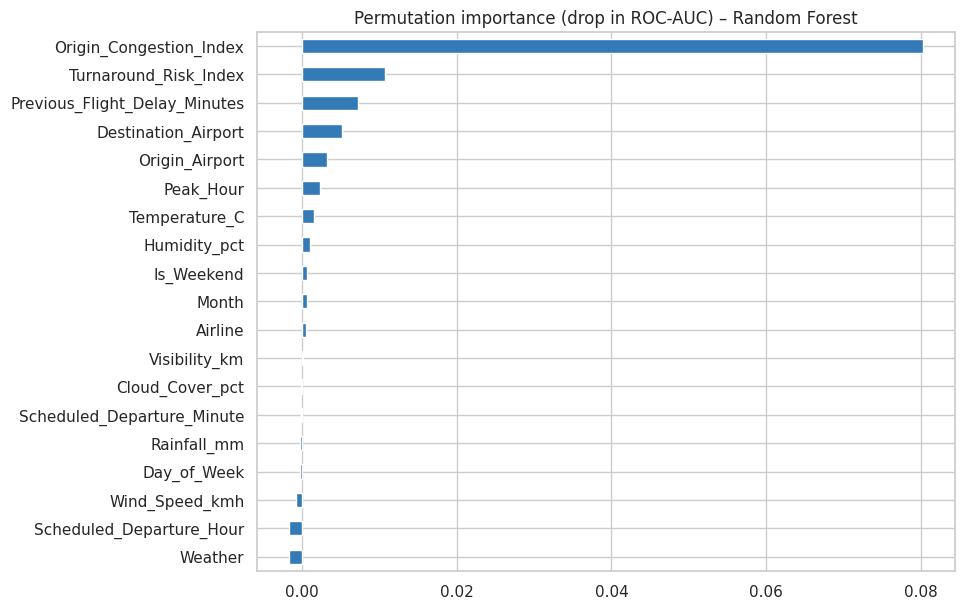

,0
Origin_Congestion_Index,0.0803
Turnaround_Risk_Index,0.0107
Previous_Flight_Delay_Minutes,0.0072
Destination_Airport,0.0051
Origin_Airport,0.0032
Peak_Hour,0.0023
Temperature_C,0.0015
Humidity_pct,0.0010


In [ ]:
sample = X_test.sample(20000, random_state=RANDOM_STATE)
imp = permutation_importance(best_model, sample, y_test.loc[sample.index], scoring="roc_auc",
                             n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp_df = pd.Series(imp.importances_mean, index=FEATURES).sort_values(ascending=True)
imp_df.plot(kind="barh", figsize=(9, 7), color="#337AB7")
plt.title(f"Permutation importance (drop in ROC-AUC) – {best_name}"); plt.show()
imp_df.sort_values(ascending=False).head(8).round(4)

## 8. Regression: how many minutes will the flight be delayed?
Predicts `Departure_Delay` (minutes) with the same features.

In [ ]:
y_train_r, y_test_r = train[TARGET_REG], test[TARGET_REG]

regs = {
    "Ridge Regression": Pipeline([("prep", make_preprocessor(scale=True)), ("reg", Ridge(alpha=1.0))]),
    "Gradient Boosting (HistGB)": Pipeline([("prep", make_preprocessor()),
                                            ("reg", HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=RANDOM_STATE))]),
}
rrows = []
for name, m in regs.items():
    m.fit(X_train, y_train_r)
    pr = np.clip(m.predict(X_test), 0, None)
    rrows.append({"Model": name, "MAE (min)": mean_absolute_error(y_test_r, pr),
                  "RMSE (min)": np.sqrt(mean_squared_error(y_test_r, pr)), "R²": r2_score(y_test_r, pr)})
    regs[name] = (m, pr)
pd.DataFrame(rrows).set_index("Model").round(3)

,MAE (min),RMSE (min),R²
Model,,,
Ridge Regression,9.861,14.131,0.449
Gradient Boosting (HistGB),7.382,12.204,0.589


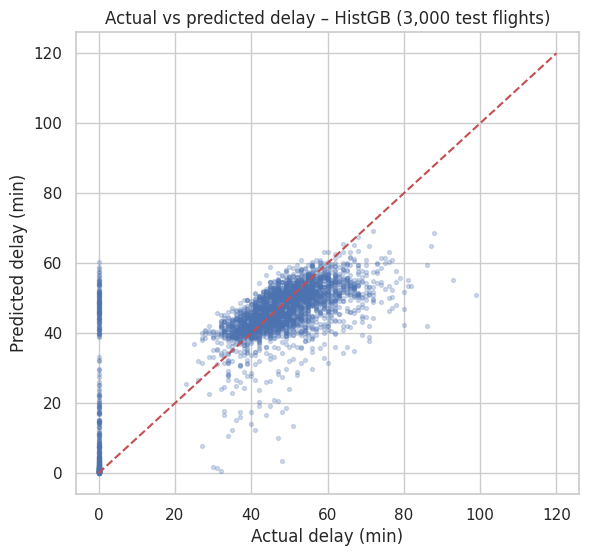

In [ ]:
m, pr = regs["Gradient Boosting (HistGB)"]
plt.figure(figsize=(6.5, 6))
plt.scatter(y_test_r.sample(3000, random_state=1), pd.Series(pr, index=y_test_r.index).loc[y_test_r.sample(3000, random_state=1).index], alpha=.25, s=8)
plt.plot([0, 120], [0, 120], "r--"); plt.xlabel("Actual delay (min)"); plt.ylabel("Predicted delay (min)")
plt.title("Actual vs predicted delay – HistGB (3,000 test flights)"); plt.show()

## 9. Predict a new flight

In [ ]:
reg_model = regs["Gradient Boosting (HistGB)"][0]

def predict_flight(**kw):
    row = pd.DataFrame([kw])[FEATURES]
    prob = best_model.predict_proba(row)[0, 1]
    minutes = max(0, reg_model.predict(row)[0])
    return {"delay_probability": round(float(prob), 3),
            "predicted_delay_minutes": round(float(minutes), 1),
            "verdict": "DELAYED" if prob >= 0.5 else "ON TIME"}

example = dict(Airline="IndiGo", Origin_Airport="BOM", Destination_Airport="DEL",
               Scheduled_Departure_Hour=18, Scheduled_Departure_Minute=30, Day_of_Week=4, Month=7, Is_Weekend=0,
               Peak_Hour=1, Weather="Rain", Temperature_C=28, Humidity_pct=75, Wind_Speed_kmh=10, Visibility_km=8,
               Rainfall_mm=6, Cloud_Cover_pct=60, Origin_Congestion_Index=88, Previous_Flight_Delay_Minutes=15,
               Turnaround_Risk_Index=45)
print(predict_flight(**example))

calm = dict(example, Peak_Hour=0, Scheduled_Departure_Hour=7, Weather="Clear/Partly Cloudy", Rainfall_mm=0,
            Origin_Congestion_Index=30, Previous_Flight_Delay_Minutes=0, Turnaround_Risk_Index=20)
print(predict_flight(**calm))

{'delay_probability': 0.867, 'predicted_delay_minutes': 57.5, 'verdict': 'DELAYED'}
{'delay_probability': 0.196, 'predicted_delay_minutes': 2.4, 'verdict': 'ON TIME'}


## 10. Save the trained models

In [ ]:
import joblib
joblib.dump({"classifier": best_model, "regressor": reg_model, "features": FEATURES}, "flight_delay_models.joblib")
print("Saved flight_delay_models.joblib")
try:
    from google.colab import files
    files.download("flight_delay_models.joblib")
except ImportError:
    pass

Saved flight_delay_models.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Conclusions (edit for your report)
1. Delays in this dataset are driven mainly by **origin congestion (by far the strongest), turnaround risk and previous-flight delay**; weather has a comparatively small effect.
2. Because ~87 % of flights are delayed, evaluate with F1 / ROC-AUC / PR-AUC, not accuracy.
3. A time-based split (train 2023–24, test 2025) gives a realistic estimate of future performance.
4. **Limitations:** the data appears synthetic and has no actual/real weather feeds or NOTAMs; delays are either 0 or ≥ 19 min; airline-level effects are weak.
5. **Future work:** real DGCA/FlightRadar data, hyperparameter tuning (Optuna), SHAP explanations, a Streamlit dashboard with live prediction.